# 08. 하이브리드 두 트랙 — 최지훈 B5~B7

제안서 3.3절. `07_cbf.ipynb`를 먼저 실행해서 `cbf`, `mf_fb` 예측값과 `results/cbf/{DS}_cbf_config.json`이 있어야 한다.

| 셀 | 트랙 | 내용 | 대략 (Video_Games) |
|---|---|---|---|
| 0~1 | | 설정, 데이터, 07·05 설정 읽기 | 1분 |
| 2 | 평점 | w 탐색 (valid RMSE) → test RMSE·MAE | 수 초 |
| 3 | 평점 | 구간별 w (cold / mid / active) | 수 초 |
| 4 | 평점 | 성공 기준 ①② 판정, 예측값 저장 | 1분 |
| 5 | Top-N | MF 다시 학습 (혜림 님 설정 그대로) → 원점수용 | 5분 |
| 6 | Top-N | 가중치 탐색 (valid ③ HR@10, 66개 조합) | 셀 안에서 예상 시간 출력 |
| 7 | Top-N | test ①②③ 평가, 성공 기준 ③ 판정 | 5~10분 |
| 8 | | 설정·결과 저장 | 수 초 |

규칙: w와 Top-N 가중치는 **valid로만** 고르고 test는 마지막에 한 번만 쓴다 (docs/EVAL_RULES.md).

In [1]:
# ===== 0. 설정 =====
import os, sys, subprocess, json, time, importlib
try:
    from google.colab import drive
    drive.mount('/content/drive')
    REPO = '/content/team10-recsys'
    if not os.path.exists(REPO):
        subprocess.run(['git', 'clone', '-q', 'https://github.com/qhfl3644/team10-recsys.git', REPO], check=True)
    else:
        subprocess.run(['git', '-C', REPO, 'pull', '-q'], check=True)
except ImportError:
    REPO = os.environ.get('TEAM10_REPO', '..')
sys.path.insert(0, REPO)
from config import *

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import src.models.cbf as cbf_mod, src.models.hybrid as hyb_mod
importlib.reload(cbf_mod); importlib.reload(hyb_mod)
from src.eval import metrics as M
from src.models.baselines import BASELINES
from src.models.mf import MF
from src.models.cbf import CBF, load_tfidf
from src.models.hybrid import (W_GRID, blend, search_w, search_w_by_group, blend_by_group,
                               RankHybrid, weight_grid, search_rank_weights)

DS = 'Video_Games'
OUT = f'{RESULT_DIR}/hybrid'
os.makedirs(OUT, exist_ok=True)
CHUNK = 256 if DS == 'Video_Games' else 64     # Toys는 상품이 많아 한 번에 처리하는 사용자를 줄임
parse_k = lambda s: None if str(s) == 'all' else int(s)
print('준비 완료:', DS)

Mounted at /content/drive
준비 완료: Video_Games


## 1. 데이터와 앞 단계 설정

- `07`의 CBF 설정(k, score_k)과 TF-IDF 행렬
- `05`의 MF 설정(k, lr, reg) — 파일이 없으면 혜림 님 노트북에서 고른 값(16, 0.01, 0.1)
- 예측값 파일: `mf_fb`(MF + 미등장 상품 CBF 대체), `cbf`

In [2]:
# ===== 1. 데이터 =====
t0 = time.time()
data = M.load_data(DS)
with open(f'{RESULT_DIR}/cbf/{DS}_cbf_config.json', encoding='utf-8') as f:
    cbf_cfg = json.load(f)
CBF_K, SCORE_K = parse_k(cbf_cfg['k']), parse_k(cbf_cfg['score_k'])
mf_cfg_path = f'{RESULT_DIR}/mf/{DS}_mf_config.json'
mf_cfg = json.load(open(mf_cfg_path, encoding='utf-8')) if os.path.exists(mf_cfg_path) else dict(k=16, lr=0.01, reg=0.1)
print(f'CBF 설정 (07): k={cbf_cfg["k"]}, score_k={cbf_cfg["score_k"]}')
print(f'MF 설정 (05): k={mf_cfg["k"]}, lr={mf_cfg["lr"]}, reg={mf_cfg["reg"]}')

P = {}
for split in ['valid', 'test']:
    df = getattr(data, split)
    P[split] = {m: M.load_predictions(DS, m, split, df) for m in ['mf', 'mf_fb', 'cbf']}
yv, yt = data.valid['rating'].values, data.test['rating'].values
gv, gt = data.group_of(data.valid['uidx'].values), data.group_of(data.test['uidx'].values)
print(f'예측값 읽기 완료 ({time.time()-t0:.0f}초)')
for split, y in [('valid', yv), ('test', yt)]:
    print(f'  {split}: ' + ', '.join(f'{m} RMSE {M.rmse(y, P[split][m]):.4f}' for m in ['mf', 'mf_fb', 'cbf']))

CBF 설정 (07): k=all, score_k=3
MF 설정 (05): k=16, lr=0.01, reg=0.1
예측값 읽기 완료 (32초)
  valid: mf RMSE 1.0906, mf_fb RMSE 1.0909, cbf RMSE 1.2064
  test: mf RMSE 1.1714, mf_fb RMSE 1.1717, cbf RMSE 1.2890


## 2. 평점 예측 트랙: w 탐색

r_hat = w · MF + (1 − w) · CBF,  w = 0, 0.05, …, 1 (21개). **valid RMSE가 가장 낮은 w**를 고른다.
w = 1이면 MF만, w = 0이면 CBF만 쓰는 것과 같다.

In [3]:
# ===== 2. w 탐색 =====
w_table, BEST_W = search_w(yv, P['valid']['mf_fb'], P['valid']['cbf'])
print(w_table.iloc[::2].round(4).to_string(index=False))
print(f'\n선택: w = {BEST_W:.2f}  (valid RMSE {w_table["rmse"].min():.4f})')
p_hyb = {s: blend(P[s]['mf_fb'], P[s]['cbf'], BEST_W) for s in ['valid', 'test']}
print(f'test: 하이브리드 RMSE {M.rmse(yt, p_hyb["test"]):.4f}  MAE {M.mae(yt, p_hyb["test"]):.4f}  '
      f'| MF(fb) {M.rmse(yt, P["test"]["mf_fb"]):.4f}  | CBF {M.rmse(yt, P["test"]["cbf"]):.4f}')

  w   rmse    mae
0.0 1.2064 0.7688
0.1 1.1816 0.7664
0.2 1.1594 0.7645
0.3 1.1400 0.7632
0.4 1.1235 0.7625
0.5 1.1100 0.7627
0.6 1.0996 0.7636
0.7 1.0925 0.7654
0.8 1.0886 0.7681
0.9 1.0881 0.7719
1.0 1.0909 0.7768

선택: w = 0.85  (valid RMSE 1.0879)
test: 하이브리드 RMSE 1.1701  MAE 0.8253  | MF(fb) 1.1717  | CBF 1.2890


## 3. 구간별 w

가설: **평점이 적은 사용자일수록 CBF가 유리하다** → cold(3~4) 구간의 w가 가장 작게(CBF 비중이 크게) 나와야 한다.
가설이라 미리 정하지 않고 구간마다 valid로 고른다.

  cold(3-4)    w = 0.90  (valid RMSE 1.1116, n=48,624)
  mid(5-9)     w = 0.85  (valid RMSE 1.0740, n=32,212)
  active(10+)  w = 0.80  (valid RMSE 1.0342, n=13,926)

RMSE (test)
model        global_mean  user_mean  item_mean   mf_fb     cbf  hybrid  hybrid_grp
group                                                                             
all               1.2949     1.2466     1.2677  1.1717  1.2890  1.1701      1.1698
cold(3-4)         1.3046     1.2896     1.2749  1.1917  1.3418  1.1908      1.1901
mid(5-9)          1.2860     1.2107     1.2617  1.1575  1.2493  1.1555      1.1555
active(10+)       1.2812     1.1737     1.2564  1.1330  1.1874  1.1306      1.1307


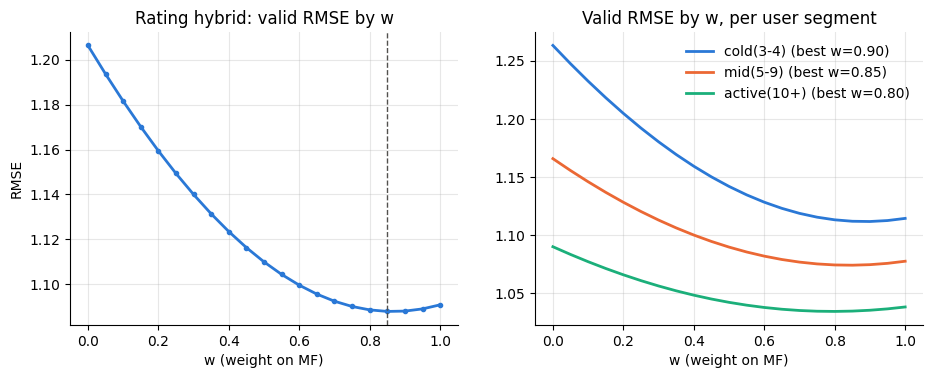

In [4]:
# ===== 3. 구간별 w =====
wg_table, W_GROUP = search_w_by_group(yv, P['valid']['mf_fb'], P['valid']['cbf'], gv)
for g in M.GROUPS:
    r = wg_table[(wg_table.group == g)]
    print(f'  {g:12s} w = {W_GROUP[g]:.2f}  (valid RMSE {r["rmse"].min():.4f}, n={int(r["n"].iloc[0]):,})')
p_hyb_g = {'valid': blend_by_group(P['valid']['mf_fb'], P['valid']['cbf'], gv, W_GROUP),
           'test': blend_by_group(P['test']['mf_fb'], P['test']['cbf'], gt, W_GROUP)}

base = {k: c().fit(data.train, data.n_users, data.n_items) for k, c in BASELINES.items() if k != 'popularity'}
ut, it = data.test['uidx'].values, data.test['iidx'].values
p_base = {k: m.predict(ut, it) for k, m in base.items()}
rt = M.rating_table({**p_base, 'mf_fb': P['test']['mf_fb'], 'cbf': P['test']['cbf'],
                     'hybrid': p_hyb['test'], 'hybrid_grp': p_hyb_g['test']}, data.test, data)
print('\nRMSE (test)')
print(rt[rt.scope == 'all'].pivot_table(index='group', columns='model', values='rmse', sort=False)
        [['global_mean', 'user_mean', 'item_mean', 'mf_fb', 'cbf', 'hybrid', 'hybrid_grp']].round(4).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(w_table['w'], w_table['rmse'], marker='o', markersize=3, linewidth=2, color='#2a78d6')
axes[0].axvline(BEST_W, color='#52514e', linestyle='--', linewidth=1)
axes[0].set_title('Rating hybrid: valid RMSE by w'); axes[0].set_xlabel('w (weight on MF)'); axes[0].set_ylabel('RMSE')
colors = {'cold(3-4)': '#2a78d6', 'mid(5-9)': '#eb6834', 'active(10+)': '#1baf7a'}
for g in M.GROUPS:
    r = wg_table[wg_table.group == g]
    axes[1].plot(r['w'], r['rmse'], linewidth=2, color=colors[g], label=f'{g} (best w={W_GROUP[g]:.2f})')
axes[1].set_title('Valid RMSE by w, per user segment'); axes[1].set_xlabel('w (weight on MF)'); axes[1].legend(frameon=False)
for ax in axes:
    ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=0.3)
fig.savefig(f'{OUT}/{DS}_rating_w.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. 성공 기준 ①② 판정 + 예측값 저장

- 기준 ①: 하이브리드 RMSE가 기준 모델 3개 모두보다 낮을 것 (점추정)
- 기준 ②: cold(3~4) 구간에서 (단일 방식 − 하이브리드)의 95% CI 상한 ≥ 0 (MF는 fallback 버전)
- 판정은 율이 님 함수(`metrics.criterion_*`)를 그대로 쓴다. 최종 집계는 율이 님이 같은 파일로 다시 한다.

In [5]:
# ===== 4. 판정 + 저장 =====
c1 = M.criterion_rating_vs_baselines(p_hyb['test'], p_base, data.test, data)
print(f'[기준 ①] 하이브리드 vs 기준 모델 3개: {"통과" if c1.attrs["passed"] else "미통과"}')
print(c1[['baseline', 'rmse_model', 'rmse_baseline', 'ci_lo', 'ci_hi', 'passed']].round(4).to_string(index=False))
for name, ph in [('hybrid (전체 w)', p_hyb['test']), ('hybrid_grp (구간별 w)', p_hyb_g['test'])]:
    c2 = M.criterion_cold_hybrid(ph, {'mf_fb': P['test']['mf_fb'], 'cbf': P['test']['cbf']}, data.test, data)
    print(f'\n[기준 ②] {name}: {"통과" if c2.attrs["passed"] else "미통과"}')
    print(c2[['single', 'n', 'rmse_hybrid', 'rmse_single', 'single_minus_hybrid', 'ci_lo', 'ci_hi', 'passed']].round(4).to_string(index=False))

for split in ['valid', 'test']:
    df = getattr(data, split)
    print(' 저장:', M.save_predictions(DS, 'hybrid', split, df, p_hyb[split]))
    print(' 저장:', M.save_predictions(DS, 'hybrid_grp', split, df, p_hyb_g[split]))

[기준 ①] 하이브리드 vs 기준 모델 3개: 통과
   baseline  rmse_model  rmse_baseline  ci_lo  ci_hi  passed
global_mean      1.1701         1.2949 0.1204 0.1288    True
  user_mean      1.1701         1.2466 0.0733 0.0794    True
  item_mean      1.1701         1.2677 0.0940 0.1017    True

[기준 ②] hybrid (전체 w): 통과
single     n  rmse_hybrid  rmse_single  single_minus_hybrid   ci_lo  ci_hi  passed
 mf_fb 48624       1.1908       1.1917                0.001 -0.0001 0.0020    True
   cbf 48624       1.1908       1.3418                0.151  0.1451 0.1573    True

[기준 ②] hybrid_grp (구간별 w): 통과
single     n  rmse_hybrid  rmse_single  single_minus_hybrid  ci_lo  ci_hi  passed
 mf_fb 48624       1.1901       1.1917               0.0016 0.0009 0.0023    True
   cbf 48624       1.1901       1.3418               0.1517 0.1454 0.1582    True
 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Video_Games/hybrid_valid.parquet
 저장: /content/drive/MyDrive/Team10_RecSys/predictions/Video_Games/hybrid_grp_valid.parqu

## 5. Top-N 트랙: 신호 모델 준비

- 인기도: log(1 + train 평점 수) (율이 님 `Popularity`)
- CBF 유사도 원점수: 07에서 고른 score_k
- MF 원점수: 혜림 님은 예측값 파일만 저장해서, **같은 설정·같은 시드로 다시 학습**한다.
  다시 학습한 valid 예측이 저장된 `mf_valid`와 같은지 확인한다.

In [6]:
# ===== 5. 신호 모델 =====
t0 = time.time()
X = load_tfidf(cbf_cfg['tfidf_path'])
cbf = CBF(X, k=CBF_K, score_k=SCORE_K).fit(data.train, data.n_users, data.n_items)
pop = BASELINES['popularity']().fit(data.train, data.n_users, data.n_items)
mf = MF(k=int(mf_cfg['k']), lr=float(mf_cfg['lr']), reg=float(mf_cfg['reg']), epochs=60, patience=5, seed=SEED)
mf.fit(data.train, data.n_users, data.n_items, valid=data.valid)
pv_mf = mf.predict(data.valid['uidx'].values, data.valid['iidx'].values)
d = np.abs(pv_mf - P['valid']['mf'])
print(f'다시 학습한 MF valid RMSE {M.rmse(yv, pv_mf):.4f} (저장본 {M.rmse(yv, P["valid"]["mf"]):.4f}), 예측 차이 최대 {d.max():.2e}')
print('→ 저장본과 같음' if d.max() < 1e-6 else '→ 저장본과 조금 다름 (아래 안내 참고)')
SIGNALS = {'pop': pop, 'cbf': cbf, 'mf': mf}
print(f'({time.time()-t0:.0f}초)')

    epoch   1  valid RMSE 1.1763
    epoch   2  valid RMSE 1.1579
    epoch   3  valid RMSE 1.1454
    epoch   5  valid RMSE 1.1274
    epoch  10  valid RMSE 1.1043
    epoch  15  valid RMSE 1.0950
    epoch  20  valid RMSE 1.0913
    epoch  25  valid RMSE 1.0908
    조기 종료: 27에폭 (최저 22에폭, valid RMSE 1.0906)
다시 학습한 MF valid RMSE 1.0906 (저장본 1.0906), 예측 차이 최대 2.38e-07
→ 저장본과 같음
(335초)


## 6. Top-N 가중치 탐색 (valid, 프로토콜 ③)

score = a·z(인기도) + b·z(CBF) + c·z(MF),  a + b + c = 1, 0.1 간격 66개 조합.
z는 사용자마다 전체 상품 안에서 표준화한 값. **valid ③(p3_users 1만 명)의 HR@10**이 가장 높은 조합을 고른다.
(1, 0, 0)이 인기도 기준 모델, (0, 1, 0)이 CBF 단독, (0, 0, 1)이 MF 단독이다.

먼저 사용자 한 묶음으로 시간을 재고 전체 예상 시간을 출력한다.

In [7]:
# ===== 6-1. 시간 측정 =====
p3 = M.load_p3_users(DS)
GRID = weight_grid(list(SIGNALS), step=0.1)
t0 = time.time()
_ = search_rank_weights(SIGNALS, data, 'valid', p3[:CHUNK], GRID, chunk=CHUNK, verbose=False)
per = (time.time() - t0) / CHUNK
print(f'조합 {len(GRID)}개, 사용자 1명당 {per*1000:.0f}ms → {len(p3):,}명 예상 {per*len(p3)/60:.1f}분')

조합 66개, 사용자 1명당 33ms → 10,000명 예상 5.5분


In [8]:
# ===== 6-2. 가중치 탐색 =====
t0 = time.time()
rw_table, _ = search_rank_weights(SIGNALS, data, 'valid', p3, GRID, chunk=CHUNK)
rw_table = rw_table.sort_values(['HR10', 'NDCG10'], ascending=False).reset_index(drop=True)
best = rw_table.iloc[0]
RANK_W = {n: float(best[f'w_{n}']) for n in SIGNALS}
single = rw_table[(rw_table[[f'w_{n}' for n in SIGNALS]] == 1).any(axis=1)]
print('상위 10개 조합')
print(rw_table.head(10).round(4).to_string(index=False))
print('\n신호 하나만 쓴 경우')
print(single.round(4).to_string(index=False))
print(f'\n선택: {RANK_W}  (valid ③ HR@10 {best["HR10"]:.4f})  ({time.time()-t0:.0f}초)')

  256/10,000명 (5초)
  2,816/10,000명 (69초)
  5,376/10,000명 (131초)
  7,936/10,000명 (193초)
상위 10개 조합
 w_pop  w_cbf  w_mf   HR10  NDCG10
   0.7    0.3   0.0 0.0503  0.0257
   0.6    0.2   0.2 0.0489  0.0260
   0.6    0.3   0.1 0.0486  0.0246
   0.5    0.2   0.3 0.0483  0.0251
   0.7    0.2   0.1 0.0473  0.0256
   0.4    0.2   0.4 0.0459  0.0234
   0.5    0.3   0.2 0.0452  0.0229
   0.8    0.2   0.0 0.0447  0.0242
   0.6    0.4   0.0 0.0437  0.0222
   0.4    0.3   0.3 0.0412  0.0209

신호 하나만 쓴 경우
 w_pop  w_cbf  w_mf   HR10  NDCG10
   1.0    0.0   0.0 0.0258  0.0135
   0.0    1.0   0.0 0.0237  0.0116
   0.0    0.0   1.0 0.0001  0.0000

선택: {'pop': 0.7, 'cbf': 0.3, 'mf': 0.0}  (valid ③ HR@10 0.0503)  (244초)


## 7. test 평가 (①②③) + 성공 기준 ③

율이 님 `metrics.ranking_eval`로 계산한다. 규칙대로 ①②도 p3_users 1만 명으로 잘라서 본다.
기준 ③: 프로토콜 ③에서 (하이브리드 − 인기도) HR@10 차이의 95% CI 하한 > 0이면 통과.

In [9]:
# ===== 7. test 평가 =====
t0 = time.time()
rh = RankHybrid(SIGNALS, RANK_W)
models = {'popularity': pop, 'cbf': cbf, 'mf': mf, 'rank_hybrid': rh}
rank_table, hits = M.ranking_eval(models, data, 'test', users=p3, chunk=CHUNK)
print(rank_table.pivot_table(index='model', columns='protocol', values='HR10', sort=False).round(4).to_string())
c3 = M.criterion_topn_vs_popularity(hits, hybrid='rank_hybrid')
print(f'\n[기준 ③] 하이브리드 HR@10 {c3["hr_hybrid"]:.4f} vs 인기도 {c3["hr_popularity"]:.4f}, '
      f'차이 {c3["hybrid_minus_popularity"]:+.4f} (95% CI {c3["ci_lo"]:+.4f} ~ {c3["ci_hi"]:+.4f}) → {"통과" if c3["passed"] else "미통과"}')

# 구간별 ③ HR@10 (콜드스타트 분석)
grp = pd.Series(data.group_of(p3), index=p3)
seg = pd.DataFrame({m: hits[(m, 'p3')].groupby(grp).mean() for m in models}).reindex(M.GROUPS)
print('\n프로토콜 ③ HR@10, 사용자 구간별 (test)')
print(seg.round(4).to_string())
print(f'({time.time()-t0:.0f}초)')

protocol         p1      p2      p3
model                              
popularity   0.4919  0.1660  0.0248
cbf          0.4055  0.3787  0.0159
mf           0.1099  0.1097  0.0002
rank_hybrid  0.5832  0.3056  0.0366

[기준 ③] 하이브리드 HR@10 0.0366 vs 인기도 0.0248, 차이 +0.0118 (95% CI +0.0075 ~ +0.0160) → 통과

프로토콜 ③ HR@10, 사용자 구간별 (test)
             popularity     cbf      mf  rank_hybrid
cold(3-4)        0.0273  0.0182  0.0004       0.0424
mid(5-9)         0.0252  0.0147  0.0000       0.0330
active(10+)      0.0146  0.0104  0.0000       0.0236
(311초)


## 8. 설정·결과 저장

In [10]:
# ===== 8. 저장 =====
for t, name in [(w_table, 'rating_w'), (wg_table, 'rating_w_group'), (rt, 'rating_test'),
                (rw_table, 'rank_weights_valid'), (rank_table, 'ranking_test'), (seg.reset_index(), 'ranking_test_by_group')]:
    t = t.copy(); t.insert(0, 'dataset', DS); t.to_csv(f'{OUT}/{DS}_{name}.csv', index=False)
cfg = dict(dataset=DS, cbf=dict(k=cbf_cfg['k'], score_k=cbf_cfg['score_k']), mf=dict(k=mf_cfg['k'], lr=mf_cfg['lr'], reg=mf_cfg['reg']),
           rating_w=BEST_W, rating_w_group=W_GROUP, rank_weights=RANK_W,
           test=dict(hybrid_rmse=M.rmse(yt, p_hyb['test']), hybrid_mae=M.mae(yt, p_hyb['test']),
                     hybrid_grp_rmse=M.rmse(yt, p_hyb_g['test']), criterion3=c3))
M.save_json(cfg, f'{OUT}/{DS}_hybrid_config.json')
print(json.dumps(cfg, ensure_ascii=False, indent=1, default=str))
print(f'\n저장 위치: {OUT}')

{
 "dataset": "Video_Games",
 "cbf": {
  "k": "all",
  "score_k": "3"
 },
 "mf": {
  "k": 16,
  "lr": 0.01,
  "reg": 0.1
 },
 "rating_w": 0.85,
 "rating_w_group": {
  "cold(3-4)": 0.9,
  "mid(5-9)": 0.85,
  "active(10+)": 0.8
 },
 "rank_weights": {
  "pop": 0.7,
  "cbf": 0.3,
  "mf": 0.0
 },
 "test": {
  "hybrid_rmse": 1.1701496683756518,
  "hybrid_mae": 0.8253062265510935,
  "hybrid_grp_rmse": 1.1698139802418057,
  "criterion3": {
   "protocol": "p3",
   "n_users": 10000,
   "hr_hybrid": 0.0366,
   "hr_popularity": 0.0248,
   "hybrid_minus_popularity": 0.011800000000000001,
   "ci_lo": 0.007500000000000003,
   "ci_hi": 0.016,
   "passed": true
  }
 }
}

저장 위치: /content/drive/MyDrive/Team10_RecSys/results/hybrid


## 사용자별 hit


In [11]:
hl = pd.concat([pd.DataFrame({'model': m, 'protocol': p, 'uidx': s.index.values, 'hit': s.values})
                for (m, p), s in hits.items()], ignore_index=True)
hl.insert(0, 'dataset', DS)
hl.to_parquet(f'{OUT}/{DS}_ranking_hits_test.parquet', index=False)
print(len(hl), '행 저장:', f'{OUT}/{DS}_ranking_hits_test.parquet')

120000 행 저장: /content/drive/MyDrive/Team10_RecSys/results/hybrid/Video_Games_ranking_hits_test.parquet
